# Student Placement Outcomes — Exploratory Data Analysis

## Project snapshot

| | |
|---|---|
| **Goal** | Describe placement and salary in a way a finance or BI audience can use: audit the file, show the KPIs, measure which gaps are large enough to matter, and compare a simple model with a naive rule. |
| **Data** | Kaggle's [Student Placement Prediction Dataset 2026](https://www.kaggle.com/datasets/sehaj1104/student-placement-prediction-dataset-2026): 100,000 rows and 26 columns. The publisher describes the file as synthetic. |
| **Approach** | Keep the structural salary check, then add a column-level quality table, segment KPIs, effect sizes, and leak-free scikit-learn pipelines. Salary is never a feature in the placement model. |
| **Evaluation** | Chi-square with Cramér's V, Welch and Mann–Whitney tests with Cohen's d, Pearson correlations with 95% confidence intervals, and 5-fold cross-validation against a naive baseline. Seed 42. |
| **Result** | 54.5% are placed. Placed students average 13.32 LPA (median 13.30). Placement is weakly separable (logistic ROC AUC 0.585 versus 0.500). Salary among placed students is moderately predictable (linear R² 0.608) from CGPA, coding score, and internships. |

> **Provenance note.** The checks below test internal consistency, not the collection process. The publisher says the records were simulated. Treat every rate in this notebook as a property of that file, not as evidence about a real campus or a real employer.

The notebook is organised as a briefing. Section 2 audits the file. Section 3 is the dashboard. Sections 4 and 5 measure placement and salary separately, because those are different questions. Section 6 puts a simple model next to the naive rule. The closing sections state what a stakeholder can take from the numbers, and what they cannot.


In [1]:
from IPython import get_ipython

_ipython = get_ipython()
if _ipython is not None:
    _ipython.run_line_magic("matplotlib", "inline")

import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy import stats

import kagglehub
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import brier_score_loss, roc_auc_score
from sklearn.model_selection import KFold, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

for candidate in (Path.cwd(), *Path.cwd().parents):
    if (candidate / "portfolio_utils").is_dir():
        REPO_ROOT = candidate
        break
else:
    raise FileNotFoundError("Could not locate the repository root containing portfolio_utils")

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from portfolio_utils import DATASETS_DIR

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 110,
    "axes.titlesize": 12,
    "axes.titleweight": "semibold",
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
    "axes.axisbelow": True,
    "grid.color": "#E6ECF0",
    "grid.linewidth": 0.6,
})

BLUE = "#1F4E79"
TEAL = "#3D7A86"
SLATE = "#8AA0B4"
INK = "#1C2830"
RUST = "#B85C38"

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 60)
pd.set_option("display.width", 140)

print(f"Repository root: {REPO_ROOT}")
print(f"Tracked dataset snapshots live in {DATASETS_DIR}. This file is downloaded, not tracked.")
print(
    "pandas", pd.__version__,
    "| numpy", np.__version__,
    "| scikit-learn", __import__("sklearn").__version__,
    "| scipy", __import__("scipy").__version__,
)


Repository root: /workspace
Tracked dataset snapshots live in /workspace/datasets. This file is downloaded, not tracked.
pandas 3.1.1 | numpy 2.5.4 | scikit-learn 1.9.1 | scipy 1.18.1


## 1. Load the source file

The CSV is the KaggleHub snapshot `sehaj1104/student-placement-prediction-dataset-2026`. The first run downloads it (about 9 MB). Later runs use the local cache. `student_id` stays in the frame until the uniqueness check in the next section.


In [2]:
dataset_dir = Path(kagglehub.dataset_download("sehaj1104/student-placement-prediction-dataset-2026"))
source_path = dataset_dir / "student_placement_prediction_dataset_2026.csv"
raw = pd.read_csv(source_path)

print(f"Rows: {len(raw):,}")
print(f"Columns: {raw.shape[1]}")
print(f"Source: {source_path}")
display(raw.head())


Rows: 100,000
Columns: 26
Source: /home/ubuntu/.cache/kagglehub/datasets/sehaj1104/student-placement-prediction-dataset-2026/versions/1/student_placement_prediction_dataset_2026.csv


,student_id,age,gender,cgpa,branch,college_tier,internships_count,projects_count,certifications_count,coding_skill_score,aptitude_score,communication_skill_score,logical_reasoning_score,hackathons_participated,github_repos,linkedin_connections,mock_interview_score,attendance_percentage,backlogs,extracurricular_score,leadership_score,volunteer_experience,sleep_hours,study_hours_per_day,placement_status,salary_package_lpa
0,1,24,Male,7.53,IT,Tier 2,4,6,1,99.238568,81.707722,57.707166,59.070073,4,1,184,72.647009,77.463863,2,63.382726,52.938240,Yes,6.7,3.6,Not Placed,0.00
1,2,21,Male,7.92,CSE,Tier 2,1,3,6,80.966123,63.116715,59.197085,78.976419,0,2,539,61.699110,88.887600,1,73.694605,60.198856,No,4.4,2.3,Not Placed,0.00
2,3,22,Female,8.60,EEE,Tier 1,0,1,1,49.177184,48.658753,92.104885,80.603331,0,2,568,87.396911,74.153265,0,63.329294,43.708803,No,8.8,5.9,Placed,11.99
3,4,24,Male,6.68,CSE,Tier 1,0,2,2,79.359084,66.376653,83.411798,64.187246,1,1,550,58.401069,87.635955,1,47.636099,56.549154,Yes,8.1,4.4,Not Placed,0.00
4,5,20,Female,8.43,IT,Tier 3,1,4,3,65.018573,61.274985,88.956331,56.163678,1,4,833,74.489201,79.120749,1,0.000000,67.268893,No,8.7,3.4,Placed,12.16


## 2. Data-quality audit

The audit keeps the original placement-salary check and extends it. A row is out of range only when it breaks a rule that was fixed before looking at how many rows failed:

- CGPA must sit on the documented 4.5–10 scale.
- Skill scores, leadership, extracurricular scores, and attendance must sit between 0 and 100.
- Age must sit between 15 and 30. That is a wide campus-age screen, not the observed minimum and maximum.
- Sleep and study hours must sit between 0 and 24.
- Counts and salary must be zero or positive. A salary of 0 is inside this rule. It is checked again, separately, against placement status.
- Categorical fields must be non-empty text.

Unplaced students are recorded at 0 LPA in the source. Those zeros stay in the file. Salary summaries and the salary model use placed students only, so the structural zero does not become a package of 0. No row is deleted and no value is imputed.


In [3]:
# Rules fixed before counting failures. None means "no upper bound".
RANGE_RULES = {
    "age": (15, 30, "15 to 30 (wide campus-age screen)"),
    "cgpa": (4.5, 10, "4.5 to 10 (documented CGPA scale)"),
    "internships_count": (0, None, "0 or more"),
    "projects_count": (0, None, "0 or more"),
    "certifications_count": (0, None, "0 or more"),
    "coding_skill_score": (0, 100, "0 to 100"),
    "aptitude_score": (0, 100, "0 to 100"),
    "communication_skill_score": (0, 100, "0 to 100"),
    "logical_reasoning_score": (0, 100, "0 to 100"),
    "hackathons_participated": (0, None, "0 or more"),
    "github_repos": (0, None, "0 or more"),
    "linkedin_connections": (0, None, "0 or more"),
    "mock_interview_score": (0, 100, "0 to 100"),
    "attendance_percentage": (0, 100, "0 to 100 percent"),
    "backlogs": (0, None, "0 or more"),
    "extracurricular_score": (0, 100, "0 to 100"),
    "leadership_score": (0, 100, "0 to 100"),
    "sleep_hours": (0, 24, "0 to 24 hours"),
    "study_hours_per_day": (0, 24, "0 to 24 hours"),
    "salary_package_lpa": (0, None, "0 or more; 0 is allowed and checked against placement below"),
}

CATEGORICAL_FIELDS = ["gender", "branch", "college_tier", "volunteer_experience", "placement_status"]
NUMERIC_FEATURES = [
    "age", "cgpa", "internships_count", "projects_count", "certifications_count",
    "coding_skill_score", "aptitude_score", "communication_skill_score", "logical_reasoning_score",
    "hackathons_participated", "github_repos", "linkedin_connections", "mock_interview_score",
    "attendance_percentage", "backlogs", "extracurricular_score", "leadership_score",
    "sleep_hours", "study_hours_per_day",
]
CATEGORICAL_FEATURES = ["gender", "branch", "college_tier", "volunteer_experience"]


def blank_mask(series):
    text = series.astype("string")
    return text.isna() | text.str.strip().eq("") | text.str.lower().isin(["nan", "none"])


def outside_range(series, low, high):
    values = pd.to_numeric(series, errors="coerce")
    invalid = ~np.isfinite(values.to_numpy(dtype=float))
    if high is None:
        invalid = invalid | (values.to_numpy(dtype=float) < low)
    else:
        invalid = invalid | (values.to_numpy(dtype=float) < low) | (values.to_numpy(dtype=float) > high)
    return invalid


column_rows = []
for column in raw.columns:
    if column in RANGE_RULES:
        low, high, rule = RANGE_RULES[column]
        missing_n = int((~np.isfinite(pd.to_numeric(raw[column], errors="coerce").to_numpy(dtype=float))).sum())
        oor_n = int(outside_range(raw[column], low, high).sum())
        handling = "Complete. No imputation, deletion, or capping."
    elif column in CATEGORICAL_FIELDS:
        rule = "Non-empty text"
        missing_n = int(blank_mask(raw[column]).sum())
        oor_n = missing_n
        handling = "Complete. No relabelling."
    elif column == "student_id":
        rule = "Identifier, checked for uniqueness separately"
        missing_n = int(raw[column].isna().sum())
        oor_n = 0
        handling = "Dropped after the uniqueness check. Not used as a feature."
    else:
        raise ValueError(f"No audit rule for {column}")
    column_rows.append({
        "Column": column,
        "Missing n": missing_n,
        "Missing %": 100 * missing_n / len(raw),
        "Range rule": rule,
        "Out-of-range n": oor_n,
        "Handling": handling,
    })

column_audit = pd.DataFrame(column_rows)
missing_total = int(column_audit["Missing n"].sum())
out_of_range_total = int(column_audit.loc[column_audit["Column"] != "student_id", "Out-of-range n"].sum())
duplicate_rows = int(raw.duplicated().sum())
duplicate_ids = int(raw["student_id"].duplicated().sum())
blank_labels = int(sum(blank_mask(raw[column]).sum() for column in CATEGORICAL_FIELDS))

not_placed = raw["placement_status"].eq("Not Placed")
placed = raw["placement_status"].eq("Placed")
unplaced_nonzero_salary = int((not_placed & raw["salary_package_lpa"].ne(0)).sum())
placed_nonpositive_salary = int((placed & raw["salary_package_lpa"].le(0)).sum())
unknown_status = int((~not_placed & ~placed).sum())

cohort_audit = pd.DataFrame([
    {"Check": "Rows", "Result": f"{len(raw):,}", "Handling": "Full cohort retained."},
    {"Check": "Columns", "Result": f"{raw.shape[1]}", "Handling": "student_id removed after the checks. 25 analytical columns remain."},
    {"Check": "Duplicate rows", "Result": f"{duplicate_rows:,}", "Handling": "No rows removed."},
    {"Check": "Duplicate student_id", "Result": f"{duplicate_ids:,}", "Handling": "No rows removed. The identifier is then dropped."},
    {"Check": "Missing values", "Result": f"{missing_total:,}", "Handling": "No imputation."},
    {"Check": "Out-of-range values", "Result": f"{out_of_range_total:,}", "Handling": "No deletion or capping."},
    {"Check": "Blank categorical values", "Result": f"{blank_labels:,}", "Handling": "No relabelling."},
    {
        "Check": "Not Placed and salary ≠ 0",
        "Result": f"{unplaced_nonzero_salary:,} of {int(not_placed.sum()):,}",
        "Handling": "Recorded zeros kept. Salary summaries and the salary model use placed students only.",
    },
    {
        "Check": "Placed and salary ≤ 0",
        "Result": f"{placed_nonpositive_salary:,} of {int(placed.sum()):,}",
        "Handling": "No rows removed or repaired.",
    },
    {
        "Check": "Placement status outside {Placed, Not Placed}",
        "Result": f"{unknown_status:,}",
        "Handling": "No rows removed.",
    },
])

print("Cohort checks")
display(cohort_audit)
print("Column audit")
audit_view = column_audit.copy()
audit_view["Missing %"] = audit_view["Missing %"].map(lambda value: f"{value:.2f}")
display(audit_view)

# Observed spans are reported as description, not as the pass/fail rule.
span_rows = []
for column, (low, high, rule) in RANGE_RULES.items():
    span_rows.append({
        "Column": column,
        "Observed min": raw[column].min(),
        "Observed max": raw[column].max(),
    })
print("Observed numeric spans")
display(pd.DataFrame(span_rows))


Cohort checks


,Check,Result,Handling
0,Rows,"100,000",Full cohort retained.
1,Columns,26,student_id removed after the checks. 25 analyt...
2,Duplicate rows,0,No rows removed.
3,Duplicate student_id,0,No rows removed. The identifier is then dropped.
4,Missing values,0,No imputation.
5,Out-of-range values,0,No deletion or capping.
6,Blank categorical values,0,No relabelling.
7,Not Placed and salary ≠ 0,"0 of 45,541",Recorded zeros kept. Salary summaries and the ...
8,Placed and salary ≤ 0,"0 of 54,459",No rows removed or repaired.
9,"Placement status outside {Placed, Not Placed}",0,No rows removed.


Column audit


,Column,Missing n,Missing %,Range rule,Out-of-range n,Handling
0,student_id,0,0.00,"Identifier, checked for uniqueness separately",0,Dropped after the uniqueness check. Not used a...
1,age,0,0.00,15 to 30 (wide campus-age screen),0,"Complete. No imputation, deletion, or capping."
2,gender,0,0.00,Non-empty text,0,Complete. No relabelling.
3,cgpa,0,0.00,4.5 to 10 (documented CGPA scale),0,"Complete. No imputation, deletion, or capping."
4,branch,0,0.00,Non-empty text,0,Complete. No relabelling.
5,college_tier,0,0.00,Non-empty text,0,Complete. No relabelling.
6,internships_count,0,0.00,0 or more,0,"Complete. No imputation, deletion, or capping."
7,projects_count,0,0.00,0 or more,0,"Complete. No imputation, deletion, or capping."
8,certifications_count,0,0.00,0 or more,0,"Complete. No imputation, deletion, or capping."
9,coding_skill_score,0,0.00,0 to 100,0,"Complete. No imputation, deletion, or capping."


Observed numeric spans


,Column,Observed min,Observed max
0,age,18.0,24.00
1,cgpa,4.5,10.00
2,internships_count,0.0,8.00
3,projects_count,0.0,13.00
4,certifications_count,0.0,11.00
5,coding_skill_score,20.0,100.00
6,aptitude_score,20.0,100.00
7,communication_skill_score,20.0,100.00
8,logical_reasoning_score,20.0,100.00
9,hackathons_participated,0.0,8.00


In [4]:
# Signals that the file may have been generated rather than extracted.
age_counts = raw["age"].value_counts().sort_index()
age_chi2, age_p = stats.chisquare(age_counts.to_numpy())
linkedin = raw["linkedin_connections"].to_numpy(dtype=float)
linkedin_ks = stats.kstest(linkedin, "uniform", args=(50, 999 - 50))
predictor_corr = raw[NUMERIC_FEATURES].corr().to_numpy(dtype=float).copy()
np.fill_diagonal(predictor_corr, np.nan)
flat_index = np.nanargmax(np.abs(predictor_corr))
row_i, col_i = np.unravel_index(flat_index, predictor_corr.shape)
max_predictor_corr = float(predictor_corr[row_i, col_i])
max_predictor_pair = (NUMERIC_FEATURES[row_i], NUMERIC_FEATURES[col_i])

generation_checks = pd.DataFrame([
    {
        "Check": "Age shares equal across 18–24",
        "Statistic": f"chi-square {age_chi2:.2f} on {len(age_counts) - 1} df",
        "p": f"{age_p:.2f}",
        "Reading": "Compatible with a uniform age draw. The pass/fail age rule above was 15–30.",
    },
    {
        "Check": "LinkedIn connections ~ Uniform[50, 999]",
        "Statistic": f"KS {linkedin_ks.statistic:.4f}",
        "p": f"{float(linkedin_ks.pvalue):.2f}",
        "Reading": "Compatible with a uniform draw on the observed bounds 50 and 999.",
    },
    {
        "Check": "Largest |correlation| among the 19 numeric predictors",
        "Statistic": f"{max_predictor_corr:.3f} ({max_predictor_pair[0]} vs {max_predictor_pair[1]})",
        "p": "—",
        "Reading": "The predictors are almost independent of each other.",
    },
])
print("Age counts")
display(age_counts.to_frame("students"))
print("Generation checks")
display(generation_checks)

# Identifier is confirmed unique, then removed. This is the original cleaning step.
if duplicate_ids != 0 or duplicate_rows != 0 or missing_total != 0:
    raise RuntimeError("Cleaning assumptions failed; do not drop the identifier and continue.")
analysis = raw.drop(columns=["student_id"]).copy()
print(f"Analytical columns: {analysis.shape[1]}")


Age counts


,students
age,
18,14229
19,14324
20,14033
21,14406
22,14386
23,14310
24,14312


Generation checks


,Check,Statistic,p,Reading
0,Age shares equal across 18–24,chi-square 6.60 on 6 df,0.36,Compatible with a uniform age draw. The pass/f...
1,"LinkedIn connections ~ Uniform[50, 999]",KS 0.0033,0.23,Compatible with a uniform draw on the observed...
2,Largest |correlation| among the 19 numeric pre...,-0.008 (projects_count vs leadership_score),—,The predictors are almost independent of each ...


Analytical columns: 25


### Reading the audit

The cohort table is clean on every rule that was set in advance: 100,000 rows, no duplicate rows, no duplicate identifiers, no missing values, no blank labels, and no out-of-range values. All 45,541 unplaced students are recorded at 0 LPA, and all 54,459 placed students have a positive package. The identifier is dropped only after that uniqueness check.

The same cleanliness is a reason to be careful. Age counts are compatible with an equal split from 18 to 24 (chi-square p = 0.36). LinkedIn connections are compatible with a uniform draw from 50 to 999 (KS p = 0.23). The largest absolute correlation among the 19 numeric predictors is 0.008. A real extract is usually messier and more entangled than this. The publisher's synthetic label and these checks point the same way.


## 3. KPI dashboard

Placement rate and the package among placed students answer different questions, so they are separate tiles. Segment tables use the same two measures. Bands are fixed as follows, and every student falls in exactly one level:

- CGPA: [4.5, 6), [6, 7), [7, 8), [8, 9), [9, 10]
- Coding score: [0, 50), [50, 70), [70, 85), [85, 100]
- Internships: 0, 1, 2, and 3 or more
- Backlogs: 0, 1, and 2 or more

Raw counts get thin in the tail (five or more backlogs, seven or more internships). The bands keep those students in the dashboard without quoting a rate for a handful of rows.


In [5]:
def add_bands(frame):
    banded_frame = frame.copy()
    banded_frame["cgpa_band"] = pd.cut(
        banded_frame["cgpa"],
        bins=[4.5, 6, 7, 8, 9, 10.0001],
        right=False,
        labels=["4.5–6", "6–7", "7–8", "8–9", "9–10"],
    )
    banded_frame.loc[banded_frame["cgpa"].eq(10), "cgpa_band"] = "9–10"
    banded_frame["coding_band"] = pd.cut(
        banded_frame["coding_skill_score"],
        bins=[0, 50, 70, 85, 100.01],
        right=False,
        labels=["Under 50", "50–70", "70–85", "85–100"],
    )
    banded_frame.loc[banded_frame["coding_skill_score"].eq(100), "coding_band"] = "85–100"
    banded_frame["internship_band"] = pd.cut(
        banded_frame["internships_count"],
        bins=[-0.1, 0, 1, 2, 100],
        labels=["0", "1", "2", "3 or more"],
    )
    banded_frame["backlog_band"] = pd.cut(
        banded_frame["backlogs"],
        bins=[-0.1, 0, 1, 100],
        labels=["0", "1", "2 or more"],
    )
    return banded_frame


def segment_table(frame, column, segment_name):
    work = frame.loc[:, [column, "placement_status", "salary_package_lpa"]].copy()
    work["_placed"] = work["placement_status"].eq("Placed")
    grouped = work.groupby(column, observed=True)
    table = grouped.agg(
        students=("_placed", "size"),
        placed=("_placed", "sum"),
        placement_rate=("_placed", "mean"),
    ).reset_index()
    medians = (
        work.loc[work["_placed"]]
        .groupby(column, observed=True)["salary_package_lpa"]
        .median()
    )
    table["median_salary_lpa"] = table[column].map(medians)
    table.insert(0, "segment", segment_name)
    table = table.rename(columns={column: "level"})
    table["level"] = table["level"].astype(str)
    table["students"] = table["students"].astype(int)
    table["placed"] = table["placed"].astype(int)
    return table


def format_kpi(table):
    view = table.copy()
    view["placement_rate"] = view["placement_rate"].map(lambda value: f"{value:.1%}")
    view["median_salary_lpa"] = view["median_salary_lpa"].map(lambda value: f"{value:.2f}")
    return view.rename(columns={
        "segment": "Segment",
        "level": "Level",
        "students": "Students",
        "placed": "Placed",
        "placement_rate": "Placement rate",
        "median_salary_lpa": "Median salary (LPA)",
    })


banded = add_bands(analysis)
for band_name in ["cgpa_band", "coding_band", "internship_band", "backlog_band"]:
    if banded[band_name].isna().any():
        raise RuntimeError(f"{band_name} has unassigned students")

n_students = len(analysis)
n_placed = int(analysis["placement_status"].eq("Placed").sum())
n_unplaced = n_students - n_placed
placement_rate = n_placed / n_students
placed_salary = analysis.loc[analysis["placement_status"].eq("Placed"), "salary_package_lpa"]
placed_mean = float(placed_salary.mean())
placed_median = float(placed_salary.median())

headline_kpis = pd.DataFrame([
    {"KPI": "Students", "Value": f"{n_students:,}", "Basis": "All rows after the audit"},
    {"KPI": "Placement rate", "Value": f"{placement_rate:.1%}", "Basis": f"{n_placed:,} placed / {n_students:,} students"},
    {"KPI": "Median salary, placed", "Value": f"{placed_median:.2f} LPA", "Basis": f"{n_placed:,} placed students"},
    {"KPI": "Mean salary, placed", "Value": f"{placed_mean:.2f} LPA", "Basis": f"{n_placed:,} placed students"},
    {"KPI": "Recorded salary, not placed", "Value": "0.00 LPA", "Basis": f"{n_unplaced:,} unplaced students, all at zero"},
])
print("Headline KPIs")
display(headline_kpis)

flat_parts = [
    segment_table(analysis, "gender", "Gender"),
    segment_table(analysis, "branch", "Branch"),
    segment_table(analysis, "college_tier", "College tier"),
    segment_table(analysis, "volunteer_experience", "Volunteer experience"),
]
kpi_flat = pd.concat(flat_parts, ignore_index=True)
band_parts = [
    segment_table(banded, "cgpa_band", "CGPA band"),
    segment_table(banded, "coding_band", "Coding score"),
    segment_table(banded, "internship_band", "Internships"),
    segment_table(banded, "backlog_band", "Backlogs"),
]
kpi_bands = pd.concat(band_parts, ignore_index=True)

print("Institution and demographic slices")
display(format_kpi(kpi_flat))
print("Academic and experience bands")
display(format_kpi(kpi_bands))

print("Raw backlog counts (tail cells are why the dashboard uses bands)")
display(analysis["backlogs"].value_counts().sort_index().to_frame("students"))
print("Raw internship counts")
display(analysis["internships_count"].value_counts().sort_index().to_frame("students"))

print("Numeric profile")
display(analysis[NUMERIC_FEATURES].describe().T.round(2))
print("Placed-student salary profile")
display(placed_salary.describe().to_frame("salary_package_lpa").T.round(2))


Headline KPIs


,KPI,Value,Basis
0,Students,"100,000",All rows after the audit
1,Placement rate,54.5%,"54,459 placed / 100,000 students"
2,"Median salary, placed",13.30 LPA,"54,459 placed students"
3,"Mean salary, placed",13.32 LPA,"54,459 placed students"
4,"Recorded salary, not placed",0.00 LPA,"45,541 unplaced students, all at zero"


Institution and demographic slices


,Segment,Level,Students,Placed,Placement rate,Median salary (LPA)
0,Gender,Female,39972,21738,54.4%,13.30
1,Gender,Male,60028,32721,54.5%,13.30
2,Branch,CSE,34818,19026,54.6%,13.30
3,Branch,Civil,10021,5529,55.2%,13.31
4,Branch,ECE,14908,8066,54.1%,13.31
5,Branch,EEE,10177,5528,54.3%,13.33
6,Branch,IT,19999,10860,54.3%,13.31
7,Branch,Mechanical,10077,5450,54.1%,13.27
8,College tier,Tier 1,20161,10988,54.5%,13.31
9,College tier,Tier 2,49955,27118,54.3%,13.29


Academic and experience bands


,Segment,Level,Students,Placed,Placement rate,Median salary (LPA)
0,CGPA band,4.5–6,6636,3536,53.3%,11.72
1,CGPA band,6–7,24250,13089,54.0%,12.55
2,CGPA band,7–8,38035,20731,54.5%,13.29
3,CGPA band,8–9,24400,13378,54.8%,14.06
4,CGPA band,9–10,6679,3725,55.8%,14.81
5,Coding score,Under 50,9145,4560,49.9%,11.95
6,Coding score,50–70,40842,21605,52.9%,12.84
7,Coding score,70–85,34279,19126,55.8%,13.62
8,Coding score,85–100,15734,9168,58.3%,14.37
9,Internships,0,22203,11172,50.3%,12.54


... (4 outputs left out)

Numeric profile


,count,mean,std,min,25%,50%,75%,max
age,100000.0,21.01,2.00,18.0,19.00,21.00,23.00,24.0
cgpa,100000.0,7.50,0.99,4.5,6.82,7.50,8.18,10.0
internships_count,100000.0,1.50,1.23,0.0,1.00,1.00,2.00,8.0
projects_count,100000.0,3.00,1.73,0.0,2.00,3.00,4.00,13.0
certifications_count,100000.0,2.01,1.42,0.0,1.00,2.00,3.00,11.0
coding_skill_score,100000.0,69.83,14.69,20.0,59.81,70.01,80.06,100.0
aptitude_score,100000.0,64.99,14.84,20.0,54.89,65.01,75.08,100.0
communication_skill_score,100000.0,67.96,13.85,20.0,58.59,67.97,77.50,100.0
logical_reasoning_score,100000.0,65.93,14.83,20.0,55.94,66.00,76.11,100.0
hackathons_participated,100000.0,1.00,1.00,0.0,0.00,1.00,2.00,8.0


Placed-student salary profile


,count,mean,std,min,25%,50%,75%,max
salary_package_lpa,54459.0,13.32,1.59,7.11,12.23,13.3,14.39,20.44


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


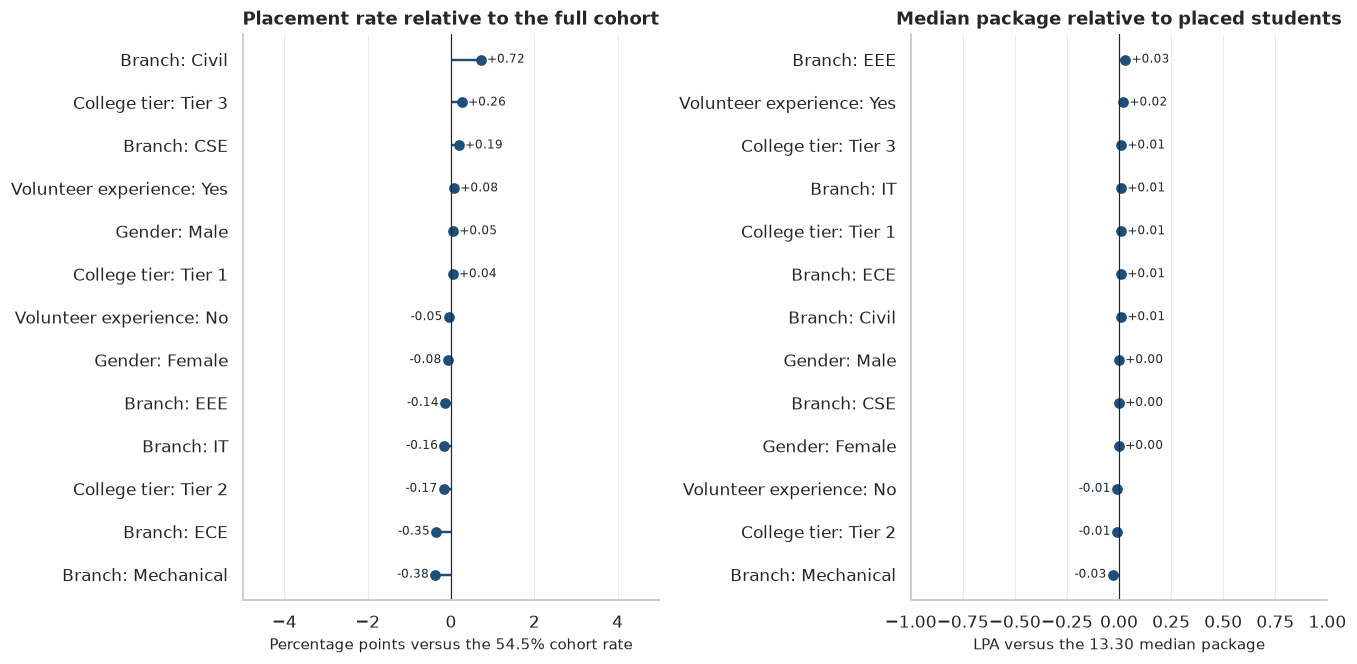

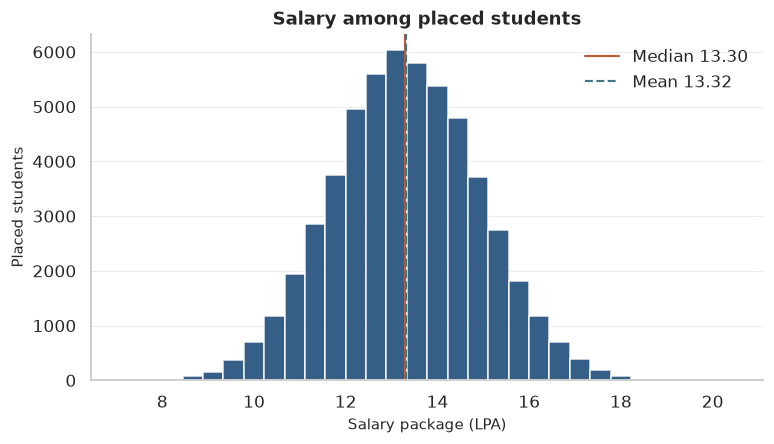

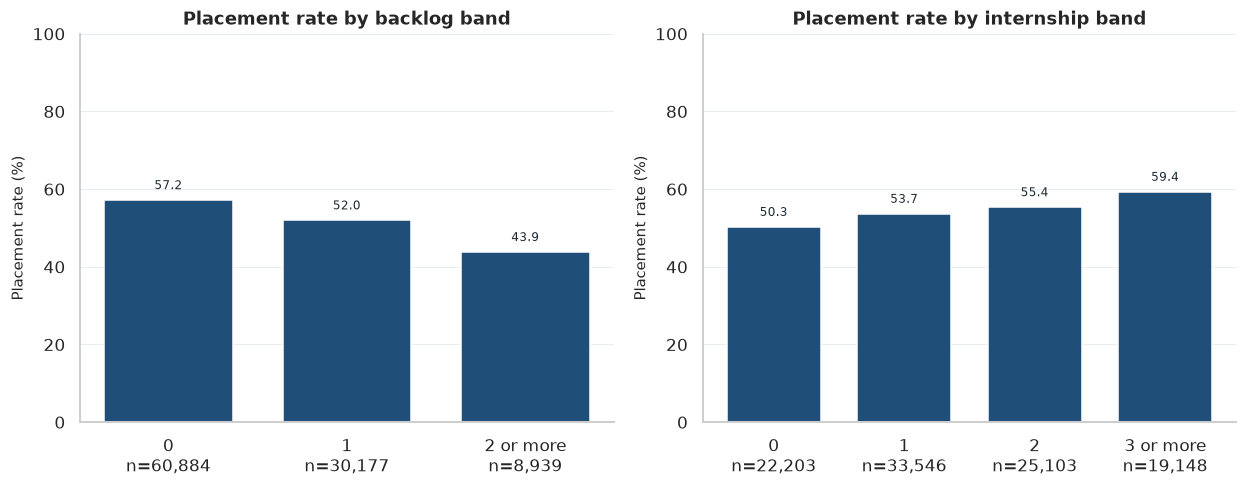

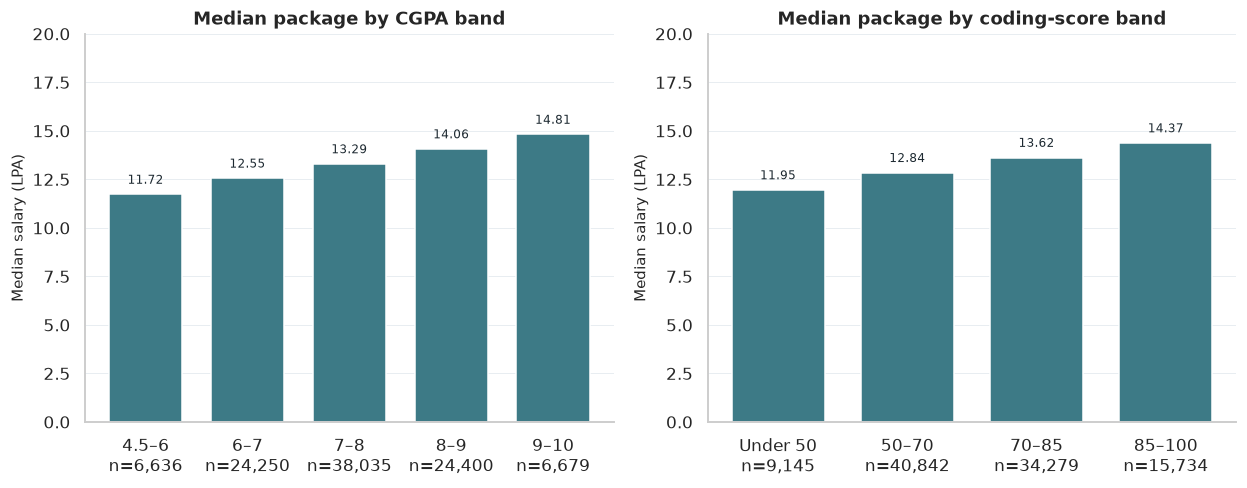

In [6]:
def style_axis(ax, grid="y"):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis=grid, color="#E6ECF0", linewidth=0.6)
    other = "x" if grid == "y" else "y"
    ax.grid(axis=other, visible=False)
    ax.set_axisbelow(True)


def lollipop(ax, labels, values, xlabel, title, xlim, value_format):
    order = np.argsort(np.asarray(values))
    labels = [labels[i] for i in order]
    values = np.asarray(values, dtype=float)[order]
    y_pos = np.arange(len(labels))
    ax.hlines(y_pos, 0, values, color=BLUE, linewidth=1.6)
    ax.plot(values, y_pos, "o", color=BLUE, markersize=6)
    ax.axvline(0, color=INK, linewidth=0.8)
    offset = 0.015 * (xlim[1] - xlim[0])
    for y_value, x_value in zip(y_pos, values):
        ha = "left" if x_value >= 0 else "right"
        ax.text(
            x_value + (offset if x_value >= 0 else -offset),
            y_value,
            format(x_value, value_format),
            va="center",
            ha=ha,
            fontsize=8,
            color=INK,
        )
    ax.set_yticks(y_pos, labels)
    ax.set_xlim(*xlim)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    style_axis(ax, grid="x")


flat_labels = (kpi_flat["segment"] + ": " + kpi_flat["level"]).tolist()
rate_gap_pp = (kpi_flat["placement_rate"] - placement_rate) * 100
salary_gap = kpi_flat["median_salary_lpa"] - placed_median

fig, axes = plt.subplots(1, 2, figsize=(12.5, 6.2))
lollipop(
    axes[0], flat_labels, rate_gap_pp,
    xlabel=f"Percentage points versus the {placement_rate:.1%} cohort rate",
    title="Placement rate relative to the full cohort",
    xlim=(-5, 5),
    value_format="+.2f",
)
lollipop(
    axes[1], flat_labels, salary_gap,
    xlabel=f"LPA versus the {placed_median:.2f} median package",
    title="Median package relative to placed students",
    xlim=(-1, 1),
    value_format="+.2f",
)
fig.tight_layout()
plt.show()

placed_salary_frame = analysis.loc[analysis["placement_status"].eq("Placed")]
fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.hist(placed_salary, bins=30, color=BLUE, alpha=0.9, edgecolor="white")
ax.axvline(placed_median, color=RUST, linewidth=1.4, label=f"Median {placed_median:.2f}")
ax.axvline(placed_mean, color=TEAL, linewidth=1.4, linestyle="--", label=f"Mean {placed_mean:.2f}")
ax.set_xlabel("Salary package (LPA)")
ax.set_ylabel("Placed students")
ax.set_title("Salary among placed students")
ax.legend()
style_axis(ax)
fig.tight_layout()
plt.show()


def grouped_bars(ax, table, values, title, ylabel, ylim, labels_text, color):
    tick_labels = [f"{level}\nn={count:,}" for level, count in zip(table["level"], table["students"])]
    x_pos = np.arange(len(tick_labels))
    ax.bar(x_pos, values, color=color, width=0.72)
    ax.set_xticks(x_pos, tick_labels)
    ax.set_ylim(*ylim)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    headroom = 0.02 * (ylim[1] - ylim[0])
    for x_value, y_value, label_text in zip(x_pos, values, labels_text):
        ax.text(x_value, y_value + headroom, label_text, ha="center", va="bottom", fontsize=8, color=INK)
    style_axis(ax)


rate_panels = [
    (banded, "backlog_band", "Backlogs", "Placement rate by backlog band"),
    (banded, "internship_band", "Internships", "Placement rate by internship band"),
]
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))
for ax, (frame, column, name, title) in zip(axes, rate_panels):
    table = segment_table(frame, column, name)
    rates = table["placement_rate"].to_numpy(dtype=float) * 100
    grouped_bars(
        ax, table, rates, title,
        ylabel="Placement rate (%)", ylim=(0, 100),
        labels_text=[f"{value:.1f}" for value in rates], color=BLUE,
    )
fig.tight_layout()
plt.show()

salary_panels = [
    (banded, "cgpa_band", "CGPA band", "Median package by CGPA band"),
    (banded, "coding_band", "Coding score", "Median package by coding-score band"),
]
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))
for ax, (frame, column, name, title) in zip(axes, salary_panels):
    table = segment_table(frame, column, name)
    salaries = table["median_salary_lpa"].to_numpy(dtype=float)
    grouped_bars(
        ax, table, salaries, title,
        ylabel="Median salary (LPA)", ylim=(0, 20),
        labels_text=[f"{value:.2f}" for value in salaries], color=TEAL,
    )
fig.tight_layout()
plt.show()


### Reading the dashboard

The tiles to pin are the cohort placement rate, 54.5%, and the placed-student median package, 13.30 LPA (mean 13.32). The salary chart is restricted to placed students because every unplaced salary is a structural zero.

Branch, college tier, gender, and volunteering sit on top of each other. Branch placement runs from 54.1% (Mechanical and ECE) to 55.2% (Civil). Median packages across those four slice families run from 13.27 LPA (Mechanical) to 13.33 LPA (EEE). The lollipop scale is wide on purpose (±5 percentage points, ±1 LPA) so a gap a stakeholder would act on would be visible. These gaps are not.

The bands that move are backlogs, internships, CGPA, and coding score, and they do not all move the same KPI. No backlogs: 57.2% placed, median 13.29 LPA. Two or more backlogs: 43.9% placed, median 13.35 LPA. Zero internships: 50.3% placed and a 12.54 LPA median. Three or more: 59.4% placed and a 14.29 LPA median. CGPA barely moves placement (53.3% in the 4.5–6 band, 55.8% in the 9–10 band) and does move the median package (11.72 to 14.81 LPA). Coding score moves both: 49.9% and 11.95 LPA under 50, versus 58.3% and 14.37 LPA at 85–100.

Five or more backlogs cover 20 students. Seven or more internships cover 96 students. Those raw levels are not quoted as KPIs.


## 4. Drivers of placement

The comparisons below are unadjusted. For each categorical field the test is a chi-square test of independence, with Cramér's V as the effect size. Yates' correction is left on for the 2×2 tables. For each numeric field the mean difference is Cohen's d (placed minus not placed, pooled standard deviation), with a Welch t-test and a two-sided Mann–Whitney test. Counts such as backlogs are skewed and tied, so the rank test is there as a check on the t-test rather than as a second discovery.

There are 4 categorical tests and 19 numeric tests, 23 in this family. A Bonferroni threshold for a 5% family-wise error rate is 0.05 / 23 ≈ 0.0022. At 100,000 rows a trivial gap can clear that bar, so the sort order is the absolute effect size. Conventional benchmarks used only as rulers, not as decisions: Cramér's V of 0.10 and Cohen's d of 0.20 are often called small.


In [7]:
def cohens_d(left, right):
    left = np.asarray(left, dtype=float)
    right = np.asarray(right, dtype=float)
    pooled_var = (
        (len(left) - 1) * left.var(ddof=1) + (len(right) - 1) * right.var(ddof=1)
    ) / (len(left) + len(right) - 2)
    return (left.mean() - right.mean()) / np.sqrt(pooled_var)


def p_text(p_value):
    if p_value < 1e-3:
        return f"{p_value:.2e}"
    return f"{p_value:.3f}"


y_placed = analysis["placement_status"].eq("Placed")
cat_rows = []
for feature in CATEGORICAL_FEATURES:
    table = pd.crosstab(analysis[feature], y_placed)
    chi2, p_value, dof, expected = stats.chi2_contingency(table)
    n_obs = int(table.to_numpy().sum())
    v = np.sqrt(chi2 / (n_obs * min(table.shape[0] - 1, table.shape[1] - 1)))
    rates = analysis.groupby(feature)["placement_status"].apply(lambda s: s.eq("Placed").mean())
    low_level, high_level = rates.idxmin(), rates.idxmax()
    cat_rows.append({
        "feature": feature,
        "chi_square": chi2,
        "df": dof,
        "p": p_value,
        "cramers_v": v,
        "min_expected": float(np.min(expected)),
        "lower_level": f"{low_level} ({rates.min():.1%})",
        "higher_level": f"{high_level} ({rates.max():.1%})",
    })
placement_cat = pd.DataFrame(cat_rows).sort_values("cramers_v", ascending=False)

num_rows = []
for feature in NUMERIC_FEATURES:
    placed_values = analysis.loc[y_placed, feature].to_numpy(dtype=float)
    other_values = analysis.loc[~y_placed, feature].to_numpy(dtype=float)
    d_value = cohens_d(placed_values, other_values)
    welch = stats.ttest_ind(placed_values, other_values, equal_var=False)
    mannwhitney = stats.mannwhitneyu(placed_values, other_values, alternative="two-sided", method="asymptotic")
    num_rows.append({
        "feature": feature,
        "placed_mean": placed_values.mean(),
        "not_placed_mean": other_values.mean(),
        "difference": placed_values.mean() - other_values.mean(),
        "cohens_d": d_value,
        "abs_d": abs(d_value),
        "welch_p": float(welch.pvalue),
        "mannwhitney_p": float(mannwhitney.pvalue),
    })
placement_num = pd.DataFrame(num_rows).sort_values("abs_d", ascending=False)
n_placement_tests = len(placement_cat) + len(placement_num)
bonferroni_placement = 0.05 / n_placement_tests

print(
    f"Placement family: {n_placement_tests} tests. "
    f"Bonferroni 5% threshold = {bonferroni_placement:.4f}."
)
print("Categorical association with placement")
cat_view = placement_cat.copy()
cat_view["p"] = cat_view["p"].map(p_text)
display(cat_view.round({"chi_square": 2, "cramers_v": 3, "min_expected": 0}))
print("Numeric association with placement (sorted by |Cohen's d|)")
num_view = placement_num.drop(columns=["abs_d"]).copy()
num_view["welch_p"] = num_view["welch_p"].map(p_text)
num_view["mannwhitney_p"] = num_view["mannwhitney_p"].map(p_text)
display(num_view.round({"placed_mean": 3, "not_placed_mean": 3, "difference": 3, "cohens_d": 3}))


Placement family: 23 tests. Bonferroni 5% threshold = 0.0022.
Categorical association with placement


,feature,chi_square,df,p,cramers_v,min_expected,lower_level,higher_level
1,branch,4.15,5,0.528,0.006,4564.0,Mechanical (54.1%),Civil (55.2%)
2,college_tier,1.46,2,0.483,0.004,9182.0,Tier 2 (54.3%),Tier 3 (54.7%)
0,gender,0.15,1,0.699,0.001,18204.0,Female (54.4%),Male (54.5%)
3,volunteer_experience,0.15,1,0.700,0.001,18233.0,No (54.4%),Yes (54.5%)


Numeric association with placement (sorted by |Cohen's d|)


,feature,placed_mean,not_placed_mean,difference,cohens_d,welch_p,mannwhitney_p
14,backlogs,0.444,0.561,-0.117,-0.166,6.06e-147,5.89e-131
2,internships_count,1.573,1.417,0.156,0.128,9.10e-91,2.72e-79
3,projects_count,3.098,2.886,0.212,0.123,1.35e-83,5.80e-75
5,coding_skill_score,70.508,69.009,1.498,0.102,5.37e-58,8.91e-57
12,mock_interview_score,70.492,69.388,1.104,0.093,4.31e-48,1.33e-46
8,logical_reasoning_score,66.424,65.343,1.082,0.073,1.58e-30,3.21e-29
7,communication_skill_score,68.369,67.473,0.896,0.065,1.97e-24,1.96e-24
6,aptitude_score,65.418,64.474,0.945,0.064,1.20e-23,2.44e-23
16,leadership_score,55.339,54.458,0.881,0.045,2.35e-12,8.99e-12
15,extracurricular_score,60.253,59.464,0.789,0.040,2.10e-10,9.79e-10


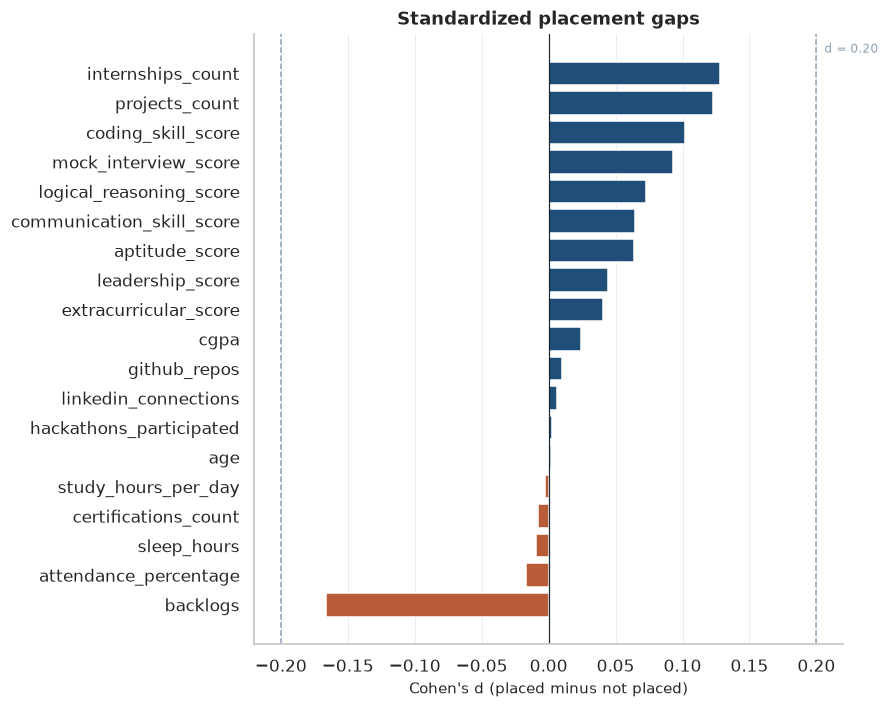

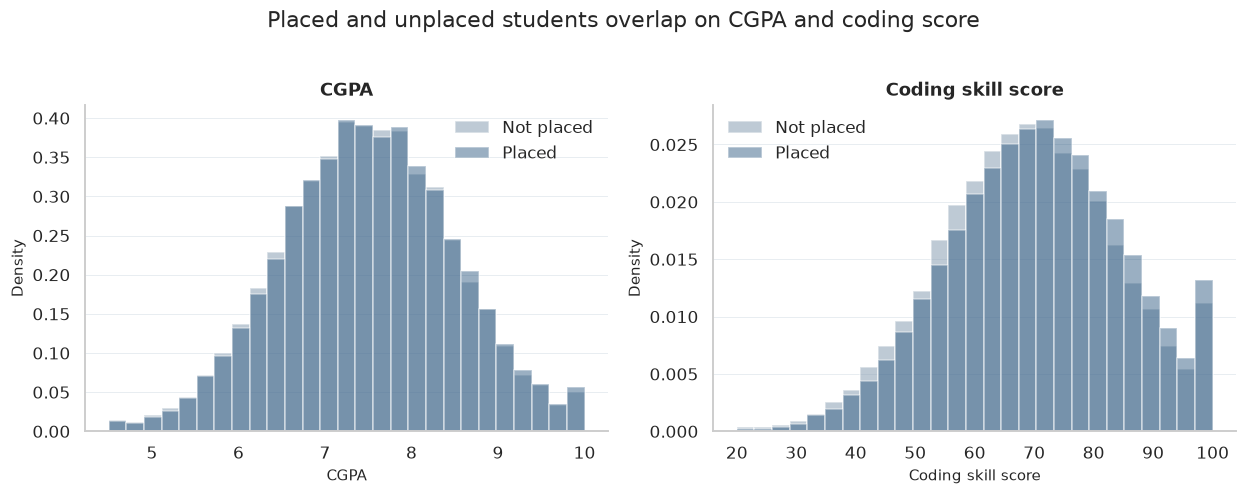

In [8]:
effect = placement_num.sort_values("cohens_d")
colors = [BLUE if value >= 0 else RUST for value in effect["cohens_d"]]
fig, ax = plt.subplots(figsize=(8.2, 6.6))
ax.barh(effect["feature"], effect["cohens_d"], color=colors)
ax.axvline(0, color=INK, linewidth=0.8)
ax.axvline(0.2, color=SLATE, linewidth=1, linestyle="--")
ax.axvline(-0.2, color=SLATE, linewidth=1, linestyle="--")
ax.text(0.2, len(effect) - 0.4, "  d = 0.20", color=SLATE, fontsize=8, va="bottom")
ax.set_xlabel("Cohen's d (placed minus not placed)")
ax.set_ylabel("")
ax.set_title("Standardized placement gaps")
style_axis(ax, grid="x")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
overlap_specs = [
    ("cgpa", "CGPA", np.linspace(4.5, 10, 28)),
    ("coding_skill_score", "Coding skill score", np.linspace(20, 100, 28)),
]
for ax, (feature, label, bins) in zip(axes, overlap_specs):
    ax.hist(
        analysis.loc[~y_placed, feature], bins=bins, density=True,
        color=SLATE, alpha=0.55, label="Not placed",
    )
    ax.hist(
        analysis.loc[y_placed, feature], bins=bins, density=True,
        color=BLUE, alpha=0.45, label="Placed",
    )
    ax.set_xlabel(label)
    ax.set_ylabel("Density")
    ax.set_title(label)
    ax.legend()
    style_axis(ax)
fig.suptitle("Placed and unplaced students overlap on CGPA and coding score", y=1.02)
fig.tight_layout()
plt.show()


### Reading the placement tests

No categorical field clears a practical bar. The largest Cramér's V is 0.006, for branch. Gender, college tier, and volunteering are about 0.001 to 0.004. The smallest expected cell is in the thousands, so this is not a sparse-table artefact. The p-values sit far above 0.05 even with 100,000 rows, which means the gaps are tiny rather than merely under-powered.

The largest numeric gap is backlogs, Cohen's d = −0.166. Internships (0.128), projects (0.123), and coding score (0.102) follow. None reaches the 0.20 line drawn on the chart. Welch and Mann–Whitney p-values agree on which of these are detectable, and both are tiny for the leading four because the sample is large. Age, study hours, sleep, certifications, hackathons, GitHub repos, and LinkedIn connections are compatible with no mean difference.

Projects are the useful contrast with salary. They have a small placement association (d = 0.123) and, in the next section, no linear association with the package. Backlogs behave the same way in the KPI table: they move the placement rate and leave the median package near 13.3 LPA. The overlap chart is the operational version of the small d for CGPA: the two groups sit on top of each other, so a CGPA cutoff would not separate placed from unplaced students.


## 5. Drivers of salary among placed students

Salary is conditional on placement. These results describe the 54,459 placed students. They do not say what an unplaced student would have been offered.

Pearson correlations use a Fisher z 95% confidence interval. Spearman correlations are the rank check. Group tests are Mann–Whitney with Cohen's d for the two binary fields, and Kruskal–Wallis with epsilon-squared for branch and college tier. Epsilon-squared can come out slightly negative when the groups are interchangeable; that is a near-zero effect, not a negative share of variance.

This is a second family of 23 tests (19 correlations and 4 group tests). The same Bonferroni ruler, about 0.0022, applies inside the family. A correlation can exclude zero and still be too small to brief.


In [9]:
placed_frame = analysis.loc[y_placed].copy()
salary = placed_frame["salary_package_lpa"].to_numpy(dtype=float)
z_crit = stats.norm.ppf(0.975)

corr_rows = []
for feature in NUMERIC_FEATURES:
    x_values = placed_frame[feature].to_numpy(dtype=float)
    r_value, p_value = stats.pearsonr(x_values, salary)
    z_value = np.arctanh(np.clip(r_value, -0.999999, 0.999999))
    se = 1 / np.sqrt(len(x_values) - 3)
    ci_low, ci_high = np.tanh([z_value - z_crit * se, z_value + z_crit * se])
    rho, spearman_p = stats.spearmanr(x_values, salary)
    corr_rows.append({
        "feature": feature,
        "pearson_r": r_value,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "pearson_p": p_value,
        "spearman_rho": rho,
        "spearman_p": spearman_p,
        "abs_r": abs(r_value),
    })
salary_corr = pd.DataFrame(corr_rows).sort_values("abs_r", ascending=False)

group_rows = []
for feature in CATEGORICAL_FEATURES:
    grouped = [values.to_numpy(dtype=float) for _, values in placed_frame.groupby(feature)["salary_package_lpa"]]
    labels = [str(level) for level, _ in placed_frame.groupby(feature)]
    medians = placed_frame.groupby(feature)["salary_package_lpa"].median()
    if len(grouped) == 2:
        statistic, p_value = stats.mannwhitneyu(grouped[0], grouped[1], alternative="two-sided", method="asymptotic")
        effect = cohens_d(grouped[0], grouped[1])
        effect_name = "Cohen's d (first level minus second)"
        test_name = "Mann–Whitney"
        stat_name = "U"
    else:
        statistic, p_value = stats.kruskal(*grouped)
        effect = (statistic - len(grouped) + 1) / (len(placed_frame) - len(grouped))
        effect_name = "epsilon-squared"
        test_name = "Kruskal–Wallis"
        stat_name = "H"
    group_rows.append({
        "feature": feature,
        "test": test_name,
        "statistic": statistic,
        "p": p_value,
        "effect": effect_name,
        "effect_value": effect,
        "median_range": f"{medians.min():.2f} to {medians.max():.2f}",
        "levels": ", ".join(labels),
    })
salary_groups = pd.DataFrame(group_rows)
n_salary_tests = len(salary_corr) + len(salary_groups)

print(
    f"Salary family, placed students only (n = {len(placed_frame):,}): {n_salary_tests} tests. "
    f"Bonferroni 5% threshold = {0.05 / n_salary_tests:.4f}."
)
print("Correlation with salary")
corr_view = salary_corr.drop(columns=["abs_r"]).copy()
corr_view["pearson_p"] = corr_view["pearson_p"].map(p_text)
corr_view["spearman_p"] = corr_view["spearman_p"].map(p_text)
display(corr_view.round({"pearson_r": 3, "ci_low": 3, "ci_high": 3, "spearman_rho": 3}))
print("Salary by category")
group_view = salary_groups.copy()
group_view["p"] = group_view["p"].map(p_text)
display(group_view.round({"statistic": 1, "effect_value": 3}))


Salary family, placed students only (n = 54,459): 23 tests. Bonferroni 5% threshold = 0.0022.
Correlation with salary


,feature,pearson_r,ci_low,ci_high,pearson_p,spearman_rho,spearman_p
1,cgpa,0.499,0.492,0.505,0.00e+00,0.485,0.00e+00
5,coding_skill_score,0.455,0.449,0.462,0.00e+00,0.441,0.00e+00
2,internships_count,0.392,0.385,0.399,0.00e+00,0.368,0.00e+00
14,backlogs,0.008,0.000,0.017,0.049,0.006,0.155
3,projects_count,-0.005,-0.013,0.004,0.259,-0.005,0.275
13,attendance_percentage,0.004,-0.004,0.012,0.340,0.004,0.352
12,mock_interview_score,-0.004,-0.012,0.004,0.353,-0.003,0.531
9,hackathons_participated,-0.004,-0.012,0.005,0.367,-0.005,0.246
11,linkedin_connections,0.004,-0.005,0.012,0.381,0.005,0.289
15,extracurricular_score,0.003,-0.005,0.012,0.437,0.003,0.476


Salary by category


,feature,test,statistic,p,effect,effect_value,median_range,levels
0,gender,Mann–Whitney,354688162.5,0.595,Cohen's d (first level minus second),-0.006,13.30 to 13.30,"Female, Male"
1,branch,Kruskal–Wallis,1.1,0.956,epsilon-squared,-0.000,13.27 to 13.33,"CSE, Civil, ECE, EEE, IT, Mechanical"
2,college_tier,Kruskal–Wallis,0.3,0.867,epsilon-squared,-0.000,13.29 to 13.31,"Tier 1, Tier 2, Tier 3"
3,volunteer_experience,Mann–Whitney,355265089.5,0.616,Cohen's d (first level minus second),-0.002,13.29 to 13.32,"No, Yes"


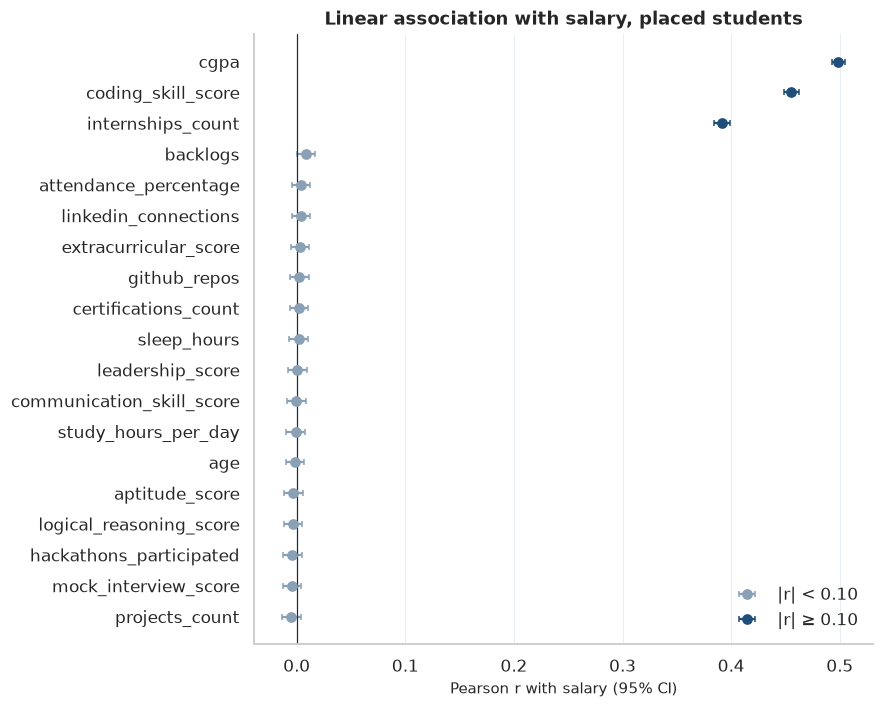

In [10]:
corr_plot = salary_corr.sort_values("pearson_r").reset_index(drop=True)
y_pos = np.arange(len(corr_plot))
material = corr_plot["abs_r"].to_numpy() >= 0.10
fig, ax = plt.subplots(figsize=(8.2, 6.6))
for mask, color, label in ((~material, SLATE, "|r| < 0.10"), (material, BLUE, "|r| ≥ 0.10")):
    subset = corr_plot.loc[mask]
    ax.errorbar(
        subset["pearson_r"],
        y_pos[mask],
        xerr=np.vstack([
            subset["pearson_r"].to_numpy() - subset["ci_low"].to_numpy(),
            subset["ci_high"].to_numpy() - subset["pearson_r"].to_numpy(),
        ]),
        fmt="o", color=color, ecolor=color, capsize=2, label=label,
    )
ax.set_yticks(y_pos, corr_plot["feature"])
ax.axvline(0, color=INK, linewidth=0.8)
ax.set_xlabel("Pearson r with salary (95% CI)")
ax.set_title("Linear association with salary, placed students")
ax.legend(loc="lower right")
style_axis(ax, grid="x")
fig.tight_layout()
plt.show()


### Reading the salary tests

Three associations are large enough to brief, and they agree in Pearson and Spearman form. CGPA has r = 0.499 (95% CI 0.492 to 0.505). Coding score has r = 0.455 (0.449 to 0.462). Internships have r = 0.392 (0.385 to 0.399). Everything else is inside about ±0.01. Backlogs have a Pearson p-value of about 0.05 and a confidence interval that starts essentially at zero; that does not survive the Bonferroni screen and it is not a pay gap a stakeholder can use. The KPI table already showed the practical version: median pay stays near 13.3 LPA across backlog bands.

Branch, college tier, gender, and volunteering do not shift the package. Kruskal–Wallis and Mann–Whitney p-values are large, epsilon-squared is about zero, and the median ranges in the table stay inside a few hundredths of an LPA. That matches the flat lollipop in the dashboard.

CGPA, coding score, and internships are almost uncorrelated with each other in this file (the predictor-correlation check in the audit). They can add up in a model. In a real campus extract those three would usually move together, so the clean split is another generation signal, not a finding to export as a theory of hiring.


## 6. Leak-free baselines

The placement model is unpenalized logistic regression (`C = inf`) inside a scikit-learn `Pipeline`. Numeric fields are standardized and categorical fields are one-hot encoded with the first level dropped. Both steps are fit on the training fold only. The target is 1 for Placed and 0 for Not Placed. **Salary is not a feature.** The identifier and the placement label are not features either. The split is stratified 5-fold, shuffled, with seed 42. There is no resampling and no threshold tuning. Threshold metrics use 0.5.

The naive comparisons are:

- a constant score, whose ROC AUC is 0.5, and whose Brier score uses the training-fold placement rate as the predicted probability
- an always-placed classifier for accuracy, balanced accuracy, precision, recall, and F1

The salary model is ordinary least squares on placed students only, with the same preprocessing and a shuffled 5-fold split (seed 42). Placement status is constant on this subset and is not a feature. The naive rule predicts the training-fold median, with the training-fold mean reported beside it. A three-feature model (CGPA, coding score, internships) is shown only as a description. Those three fields were chosen after the correlation table, so that cross-validated score is not a pre-specified confirmation. The all-feature model uses every non-leaking column rather than a screened subset.

Coefficients come from a refit on all rows of the relevant cohort after the cross-validation scores are computed. Numeric coefficients are per one full-sample standard deviation. Categorical coefficients are versus the dropped reference level.


Placement model, mean of 5 stratified folds (seed 42)


,Rule,ROC AUC,Brier,Accuracy,Balanced accuracy,Precision,Recall,F1
0,Logistic regression,0.585,0.242,0.570,0.550,0.579,0.772,0.662
1,Always predict Placed,—,—,0.545,0.500,0.545,1.000,0.705
2,Constant probability at the training placement...,0.500,0.248,—,—,—,—,—


Fold SD uses the sample standard deviation (ddof = 1).


,metric,mean,fold_sd
0,roc_auc,0.585,0.005
1,balanced_accuracy,0.550,0.003
2,accuracy,0.570,0.003
3,precision,0.579,0.002
4,recall,0.772,0.007
5,f1,0.662,0.003
6,brier,0.242,0.001


Dropped reference levels: {'gender': 'Female', 'branch': 'CSE', 'college_tier': 'Tier 1', 'volunteer_experience': 'No'}
Intercept: 0.184


,feature,coefficient,odds_ratio,unit
14,backlogs,-0.168,0.845,per 1 SD
2,internships_count,0.132,1.141,per 1 SD
3,projects_count,0.128,1.136,per 1 SD
5,coding_skill_score,0.105,1.111,per 1 SD
12,mock_interview_score,0.094,1.099,per 1 SD
8,logical_reasoning_score,0.075,1.077,per 1 SD
7,communication_skill_score,0.066,1.069,per 1 SD
6,aptitude_score,0.066,1.068,per 1 SD
16,leadership_score,0.046,1.047,per 1 SD
15,extracurricular_score,0.039,1.040,per 1 SD


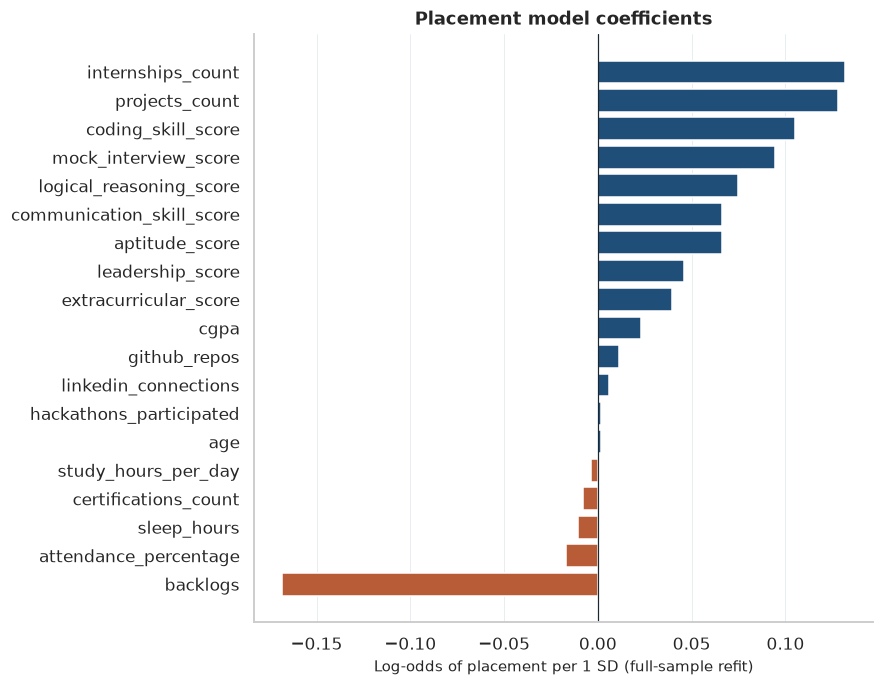

In [11]:
y = analysis["placement_status"].map({"Placed": 1, "Not Placed": 0}).astype(int)
if set(y.unique()) != {0, 1} or y.isna().any():
    raise RuntimeError("Placement target did not map cleanly.")

feature_columns = NUMERIC_FEATURES + CATEGORICAL_FEATURES
forbidden = {"salary_package_lpa", "placement_status", "student_id"}
if forbidden & set(feature_columns):
    raise RuntimeError("Leakage columns entered the feature list.")
X = analysis[feature_columns]

preprocessor = ColumnTransformer(transformers=[
    ("numeric", StandardScaler(), NUMERIC_FEATURES),
    ("categorical", OneHotEncoder(drop="first", sparse_output=False), CATEGORICAL_FEATURES),
])
placement_pipe = Pipeline(steps=[
    ("prepare", preprocessor),
    ("model", LogisticRegression(C=np.inf, solver="lbfgs", max_iter=1000, random_state=SEED)),
])
placement_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
placement_scoring = {
    "roc_auc": "roc_auc",
    "balanced_accuracy": "balanced_accuracy",
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "neg_brier": "neg_brier_score",
}
placement_cv_result = cross_validate(
    placement_pipe, X, y, cv=placement_cv, scoring=placement_scoring, n_jobs=1,
)

baseline_auc = []
baseline_brier = []
for train_idx, test_idx in placement_cv.split(X, y):
    probability = np.full(len(test_idx), y.iloc[train_idx].mean())
    y_test = y.iloc[test_idx]
    baseline_auc.append(roc_auc_score(y_test, probability))
    baseline_brier.append(brier_score_loss(y_test, probability))
baseline_auc = np.asarray(baseline_auc)
baseline_brier = np.asarray(baseline_brier)

majority = DummyClassifier(strategy="most_frequent")
majority_result = cross_validate(
    majority, X, y, cv=placement_cv,
    scoring={
        "balanced_accuracy": "balanced_accuracy",
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
    },
    n_jobs=1,
)

def metric_mean(result, name, negate=False):
    values = np.asarray(result[f"test_{name}"], dtype=float)
    if negate:
        values = -values
    return float(values.mean()), float(values.std(ddof=1)), values


placement_metrics = {}
for name in ["roc_auc", "balanced_accuracy", "accuracy", "precision", "recall", "f1"]:
    placement_metrics[name] = metric_mean(placement_cv_result, name)
placement_metrics["brier"] = metric_mean(placement_cv_result, "neg_brier", negate=True)
majority_metrics = {
    name: metric_mean(majority_result, name)
    for name in ["balanced_accuracy", "accuracy", "precision", "recall", "f1"]
}

comparison = pd.DataFrame([
    {
        "Rule": "Logistic regression",
        "ROC AUC": f"{placement_metrics['roc_auc'][0]:.3f}",
        "Brier": f"{placement_metrics['brier'][0]:.3f}",
        "Accuracy": f"{placement_metrics['accuracy'][0]:.3f}",
        "Balanced accuracy": f"{placement_metrics['balanced_accuracy'][0]:.3f}",
        "Precision": f"{placement_metrics['precision'][0]:.3f}",
        "Recall": f"{placement_metrics['recall'][0]:.3f}",
        "F1": f"{placement_metrics['f1'][0]:.3f}",
    },
    {
        "Rule": "Always predict Placed",
        "ROC AUC": "—",
        "Brier": "—",
        "Accuracy": f"{majority_metrics['accuracy'][0]:.3f}",
        "Balanced accuracy": f"{majority_metrics['balanced_accuracy'][0]:.3f}",
        "Precision": f"{majority_metrics['precision'][0]:.3f}",
        "Recall": f"{majority_metrics['recall'][0]:.3f}",
        "F1": f"{majority_metrics['f1'][0]:.3f}",
    },
    {
        "Rule": "Constant probability at the training placement rate",
        "ROC AUC": f"{baseline_auc.mean():.3f}",
        "Brier": f"{baseline_brier.mean():.3f}",
        "Accuracy": "—",
        "Balanced accuracy": "—",
        "Precision": "—",
        "Recall": "—",
        "F1": "—",
    },
])
print("Placement model, mean of 5 stratified folds (seed 42)")
display(comparison)
fold_detail = pd.DataFrame({
    "metric": ["roc_auc", "balanced_accuracy", "accuracy", "precision", "recall", "f1", "brier"],
    "mean": [placement_metrics[name][0] for name in ["roc_auc", "balanced_accuracy", "accuracy", "precision", "recall", "f1", "brier"]],
    "fold_sd": [placement_metrics[name][1] for name in ["roc_auc", "balanced_accuracy", "accuracy", "precision", "recall", "f1", "brier"]],
})
print("Fold SD uses the sample standard deviation (ddof = 1).")
display(fold_detail.round(3))

placement_pipe.fit(X, y)
if int(np.max(placement_pipe.named_steps["model"].n_iter_)) >= 1000:
    raise RuntimeError("Logistic regression did not converge.")
encoder = placement_pipe.named_steps["prepare"].named_transformers_["categorical"]
encoded_names = list(encoder.get_feature_names_out(CATEGORICAL_FEATURES))
coef_names = NUMERIC_FEATURES + encoded_names
coefficients = placement_pipe.named_steps["model"].coef_.ravel()
placement_coef = pd.DataFrame({
    "feature": coef_names,
    "coefficient": coefficients,
    "odds_ratio": np.exp(coefficients),
    "unit": ["per 1 SD"] * len(NUMERIC_FEATURES) + ["versus reference level"] * len(encoded_names),
})
placement_coef["abs_coefficient"] = placement_coef["coefficient"].abs()
placement_coef = placement_coef.sort_values("abs_coefficient", ascending=False)
references = [levels[0] for levels in encoder.categories_]
print("Dropped reference levels:", dict(zip(CATEGORICAL_FEATURES, references)))
print(f"Intercept: {float(placement_pipe.named_steps['model'].intercept_[0]):.3f}")
display(placement_coef.drop(columns=["abs_coefficient"]).round(3))

numeric_coef = (
    placement_coef.loc[placement_coef["unit"].eq("per 1 SD")]
    .sort_values("coefficient")
)
fig, ax = plt.subplots(figsize=(8.2, 6.4))
bar_colors = [BLUE if value >= 0 else RUST for value in numeric_coef["coefficient"]]
ax.barh(numeric_coef["feature"], numeric_coef["coefficient"], color=bar_colors)
ax.axvline(0, color=INK, linewidth=0.8)
ax.set_xlabel("Log-odds of placement per 1 SD (full-sample refit)")
ax.set_title("Placement model coefficients")
style_axis(ax, grid="x")
fig.tight_layout()
plt.show()


Salary model, placed students only (n = 54,459), mean of 5 folds


,Rule,R2,R2 fold SD,MAE (LPA),MAE fold SD,RMSE (LPA),RMSE fold SD
0,"All allowed features, linear regression",0.608,0.007,0.797,0.008,0.997,0.009
1,CGPA + coding score + internships (chosen afte...,0.608,0.007,0.796,0.008,0.997,0.009
2,Training-fold median,-0.000,0.000,1.274,0.009,1.592,0.012
3,Training-fold mean,-0.000,0.000,1.274,0.009,1.592,0.012


Intercept (LPA): 13.318


,feature,coefficient_lpa,unit
1,cgpa,0.786,per 1 SD
5,coding_skill_score,0.726,per 1 SD
2,internships_count,0.628,per 1 SD
21,branch_ECE,-0.037,versus reference level
26,college_tier_Tier 3,0.018,versus reference level
24,branch_Mechanical,0.013,versus reference level
20,branch_Civil,-0.010,versus reference level
23,branch_IT,-0.010,versus reference level
22,branch_EEE,-0.009,versus reference level
4,certifications_count,0.008,per 1 SD


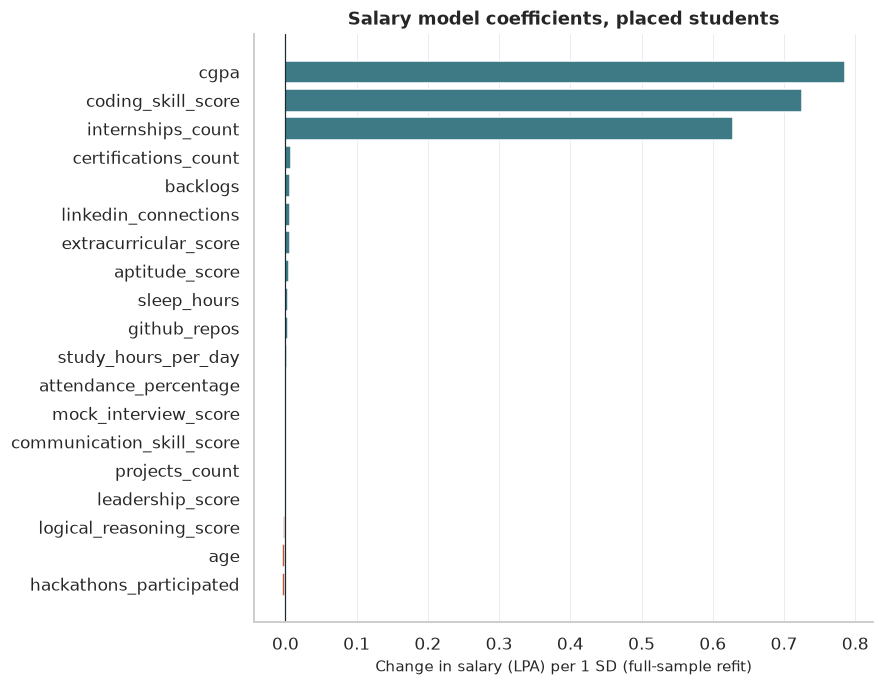

In [12]:
salary_X = placed_frame[feature_columns]
salary_y = placed_frame["salary_package_lpa"]
salary_cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
salary_scoring = {"r2": "r2", "mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error"}

salary_preprocessor = ColumnTransformer(transformers=[
    ("numeric", StandardScaler(), NUMERIC_FEATURES),
    ("categorical", OneHotEncoder(drop="first", sparse_output=False), CATEGORICAL_FEATURES),
])
salary_pipe = Pipeline(steps=[
    ("prepare", salary_preprocessor),
    ("model", LinearRegression()),
])
simple_pipe = Pipeline(steps=[
    ("prepare", StandardScaler()),
    ("model", LinearRegression()),
])
simple_features = ["cgpa", "coding_skill_score", "internships_count"]

full_salary_cv = cross_validate(salary_pipe, salary_X, salary_y, cv=salary_cv, scoring=salary_scoring, n_jobs=1)
simple_salary_cv = cross_validate(
    simple_pipe, placed_frame[simple_features], salary_y, cv=salary_cv, scoring=salary_scoring, n_jobs=1,
)
median_cv = cross_validate(
    DummyRegressor(strategy="median"), salary_X, salary_y, cv=salary_cv, scoring=salary_scoring, n_jobs=1,
)
mean_cv = cross_validate(
    DummyRegressor(strategy="mean"), salary_X, salary_y, cv=salary_cv, scoring=salary_scoring, n_jobs=1,
)

def regression_row(label, result):
    r2, r2_sd, _ = metric_mean(result, "r2")
    mae, mae_sd, _ = metric_mean(result, "mae", negate=True)
    rmse, rmse_sd, _ = metric_mean(result, "rmse", negate=True)
    return {
        "Rule": label,
        "R2": f"{r2:.3f}",
        "R2 fold SD": f"{r2_sd:.3f}",
        "MAE (LPA)": f"{mae:.3f}",
        "MAE fold SD": f"{mae_sd:.3f}",
        "RMSE (LPA)": f"{rmse:.3f}",
        "RMSE fold SD": f"{rmse_sd:.3f}",
    }

salary_comparison = pd.DataFrame([
    regression_row("All allowed features, linear regression", full_salary_cv),
    regression_row("CGPA + coding score + internships (chosen after EDA)", simple_salary_cv),
    regression_row("Training-fold median", median_cv),
    regression_row("Training-fold mean", mean_cv),
])
print(f"Salary model, placed students only (n = {len(placed_frame):,}), mean of 5 folds")
display(salary_comparison)

salary_pipe.fit(salary_X, salary_y)
salary_encoder = salary_pipe.named_steps["prepare"].named_transformers_["categorical"]
salary_names = NUMERIC_FEATURES + list(salary_encoder.get_feature_names_out(CATEGORICAL_FEATURES))
salary_coef = pd.DataFrame({
    "feature": salary_names,
    "coefficient_lpa": salary_pipe.named_steps["model"].coef_.ravel(),
    "unit": ["per 1 SD"] * len(NUMERIC_FEATURES) + ["versus reference level"] * (len(salary_names) - len(NUMERIC_FEATURES)),
})
salary_coef["abs_coefficient"] = salary_coef["coefficient_lpa"].abs()
salary_coef = salary_coef.sort_values("abs_coefficient", ascending=False)
print(f"Intercept (LPA): {float(salary_pipe.named_steps['model'].intercept_):.3f}")
display(salary_coef.drop(columns=["abs_coefficient"]).round(3))

salary_numeric = salary_coef.loc[salary_coef["unit"].eq("per 1 SD")].sort_values("coefficient_lpa")
fig, ax = plt.subplots(figsize=(8.2, 6.4))
bar_colors = [TEAL if value >= 0 else RUST for value in salary_numeric["coefficient_lpa"]]
ax.barh(salary_numeric["feature"], salary_numeric["coefficient_lpa"], color=bar_colors)
ax.axvline(0, color=INK, linewidth=0.8)
ax.set_xlabel("Change in salary (LPA) per 1 SD (full-sample refit)")
ax.set_title("Salary model coefficients, placed students")
style_axis(ax, grid="x")
fig.tight_layout()
plt.show()


### Reading the models

The placement model ranks students only slightly better than a coin toss organised around the base rate. Mean ROC AUC is 0.585, against 0.500 for a constant score. Mean Brier score is 0.242, against 0.248 for predicting the training placement rate every time. At a 0.5 threshold, accuracy is 0.570 against 0.545 for always predicting Placed, and balanced accuracy is 0.550 against 0.500.

F1 tells the opposite story if it is quoted alone. The model F1 is 0.662. The always-placed rule has F1 0.705, because its recall is 1 and its precision is the placement rate. The model's precision is 0.579 and its recall is 0.772. A careers team that cannot afford to miss a placed student would prefer the naive rule on F1. A team that needs a ranking would look at ROC AUC and would still see a weak score. I would not screen students with it.

The adjusted coefficients line up with the unadjusted effect sizes. Backlogs, internships, projects, and coding score lead, and the category contrasts are smaller. Reference levels are the dropped first categories printed above the coefficient table (Female, CSE, Tier 1, and no volunteer experience, under the encoder's default sort). The near-match between adjusted and unadjusted rankings is what almost-independent predictors produce. It is not evidence that the associations are causal.

On placed students, the linear model has R² 0.608 and MAE 0.797 LPA. Predicting the training-fold median has MAE 1.274 LPA, and predicting the training-fold mean is the same at three decimals. RMSE falls from 1.592 LPA to 0.997 LPA. The three-feature model, which was specified after seeing the correlations, matches the full model (R² 0.608, MAE 0.796). Extra fields do not earn a place in the equation. The salary coefficients are 0.786 LPA per standard deviation of CGPA, 0.726 for coding score, and 0.628 for internships. The largest category contrast is −0.037 LPA (ECE versus the CSE reference).


## Key findings and business recommendations

The numbers below are the ones computed in the tables above.

**The file passes a structural audit and still should not be briefed as a real extract.** There are 100,000 rows and 26 columns, with no duplicate rows, no duplicate student IDs, no missing values, no blank labels, and no values outside the range rules. All 45,541 unplaced students are at 0 LPA, and all 54,459 placed students have a positive package. Nothing was imputed or deleted. Age is compatible with an equal 18–24 draw (chi-square p = 0.36), LinkedIn connections are compatible with Uniform[50, 999] (KS p = 0.23), and the largest absolute correlation among the 19 numeric predictors is 0.008.

**Pin two KPIs, not one.** The placement rate is 54.5% (54,459 of 100,000). Among placed students the mean package is 13.32 LPA and the median is 13.30 LPA. Put the denominator on the tile. Do not average salary over the whole file: that average mixes real packages with 45,541 structural zeros.

**Do not rank branch, tier, gender, or volunteering.** Branch placement runs from 54.1% to 55.2%. The other three slices sit inside that band. The largest Cramér's V is 0.006. Median packages across these slices run from 13.27 to 13.33 LPA. A dashboard that colours those groups as winners and laggards would be inventing a gap.

**Treat "who is placed" and "what they are paid" as separate stories.** No backlogs: 57.2% placed, median 13.29 LPA. Two or more backlogs: 43.9% placed, median 13.35 LPA. Cohen's d for backlogs is −0.166, the largest placement gap, and it is still below the usual 0.20 ruler for a small effect. Internships move both outcomes, from 50.3% and 12.54 LPA with none to 59.4% and 14.29 LPA with three or more (d = 0.128). Projects have a similar placement association (d = 0.123) and no salary association. CGPA barely moves placement (53.3% to 55.8% across the outer bands) and moves the median package from 11.72 to 14.81 LPA (r = 0.499, 95% CI 0.492 to 0.505). Coding score moves both (r = 0.455 for salary).

**Show the naive rule beside any model, and do not ship the placement score.** With salary excluded, 5-fold logistic regression reaches ROC AUC 0.585 against 0.500, and accuracy 0.570 against 0.545. Its F1, 0.662, is worse than the always-placed F1 of 0.705. For pay, once a student is placed, linear regression reaches R² 0.608 and MAE 0.797 LPA, against 1.274 LPA for the training-fold median. CGPA, coding score, and internships match that full model. Those three were chosen after looking at the correlations; the full model was not screened that way and lands in the same place.

**Recommendations**

1. Publish placement rate and median placed salary as two tiles, each with its denominator. Keep mean salary as a secondary figure (13.32 LPA) so it is not confused with the median (13.30).
2. Leave branch, college tier, gender, and volunteering off the front page. Keep them in an appendix with sample size, for the moment someone asks. The honest answer is that this file does not separate those groups.
3. If the audience wants drivers, show backlog and internship bands for placement, and CGPA, coding, and internship bands for pay. Quote the rate and the median, then the effect size. A p-value at this sample size is a weak briefing line. Twenty-three tests in each family put a Bonferroni 5% line at 0.0022.
4. Keep the baseline in the same table as the model. For placement, lead with ROC AUC and balanced accuracy, and show F1 only next to the always-placed F1. For salary, lead with MAE in LPA next to the median rule.
5. Do not use these scores for a hiring, admissions, or pay decision. The associations are observational, the salary results are conditional on already being placed, and the file behaves like a simulator with a few planted relationships. The habit worth keeping is the method: reconcile status with the amount, separate the chance of an outcome from the size of the outcome, and put the naive rule on the page.


## Limitations and next steps

- The publisher describes the file as synthetic. The uniform age and LinkedIn checks, the 0.008 ceiling on predictor correlations, and the perfect placement-salary consistency agree with that description. These are not estimates for a real campus, and they are not a workforce or payroll study for any employer.
- The design is observational. A coefficient is an association inside this file. It is not the effect of adding an internship, clearing a backlog, or changing a CGPA.
- Salary analysis is conditional on placement. The structural zeros are real in the file and uninformative as pay. Nothing here says what an unplaced student would have earned.
- Twenty-three placement tests and twenty-three salary tests were run. Several tiny correlations will look "significant" if the briefing quotes p-values and ignores effect size. The Bonferroni line used above is 0.0022 inside each family.
- The three-feature salary model was chosen after the correlation table. Its cross-validated score is a description of that choice. The all-feature model is the pre-specified baseline, and it does not improve on those three fields.
- Five or more backlogs cover 20 students, and seven or more internships cover 96. Bands stop those cells from being read as precise rates. They also hide any non-linear jump inside the top band.
- There is no employer, city, role, or year. Amounts are in LPA. A 0.5 classification threshold was not chosen from a cost of false positives and false negatives.
- Default regularization was turned off for the logistic regression (`C = inf`) so the coefficients stay on the log-odds scale. There was no hyperparameter search and no nested cross-validation.

A next step, if a real extract ever replaces this file, is to repeat this audit and these two baselines before any more flexible model. Pre-specify the slices and the decision threshold with the person who will use the dashboard. If the real file is entangled in the way operational data usually is, the independent-predictor picture in this notebook will not survive, and that is the result worth reporting.


In [13]:
# Lock the rounded figures quoted in the findings. If a figure moves, update that section in the same edit.
expected = {
    "rows": 100_000,
    "duplicate_rows": 0,
    "duplicate_ids": 0,
    "missing_total": 0,
    "out_of_range_total": 0,
    "blank_labels": 0,
    "unplaced_nonzero_salary": 0,
    "placed_nonpositive_salary": 0,
    "n_placed": 54_459,
    "n_unplaced": 45_541,
    "placement_rate_pct": 54.5,
    "placed_mean_lpa": 13.32,
    "placed_median_lpa": 13.30,
    "placement_tests": 23,
    "salary_tests": 23,
    "top_placement_feature": "backlogs",
    "d_backlogs": -0.166,
    "d_internships": 0.128,
    "d_projects": 0.123,
    "d_coding": 0.102,
    "max_cramers_v": 0.006,
    "r_cgpa": 0.499,
    "r_cgpa_lo": 0.492,
    "r_cgpa_hi": 0.505,
    "r_coding": 0.455,
    "r_coding_lo": 0.449,
    "r_coding_hi": 0.462,
    "r_internships": 0.392,
    "r_internships_lo": 0.385,
    "r_internships_hi": 0.399,
    "auc": 0.585,
    "accuracy": 0.570,
    "balanced_accuracy": 0.550,
    "f1": 0.662,
    "precision": 0.579,
    "recall": 0.772,
    "brier": 0.242,
    "majority_accuracy": 0.545,
    "majority_f1": 0.705,
    "baseline_auc": 0.500,
    "baseline_brier": 0.248,
    "salary_r2": 0.608,
    "salary_mae": 0.797,
    "simple_r2": 0.608,
    "simple_mae": 0.796,
    "median_mae": 1.274,
    "max_predictor_corr": 0.008,
    "age_p": 0.36,
    "linkedin_p": 0.23,
}

branch = kpi_flat.loc[kpi_flat["segment"].eq("Branch")]
flat_median_min = round(float(kpi_flat["median_salary_lpa"].min()), 2)
flat_median_max = round(float(kpi_flat["median_salary_lpa"].max()), 2)
band_lookup = {(row.segment, row.level): row for row in kpi_bands.itertuples(index=False)}

actual = {
    "rows": len(raw),
    "duplicate_rows": duplicate_rows,
    "duplicate_ids": duplicate_ids,
    "missing_total": missing_total,
    "out_of_range_total": out_of_range_total,
    "blank_labels": blank_labels,
    "unplaced_nonzero_salary": unplaced_nonzero_salary,
    "placed_nonpositive_salary": placed_nonpositive_salary,
    "n_placed": n_placed,
    "n_unplaced": n_unplaced,
    "placement_rate_pct": round(placement_rate * 100, 1),
    "placed_mean_lpa": round(placed_mean, 2),
    "placed_median_lpa": round(placed_median, 2),
    "placement_tests": n_placement_tests,
    "salary_tests": n_salary_tests,
    "top_placement_feature": placement_num.iloc[0]["feature"],
    "d_backlogs": round(float(placement_num.set_index("feature").loc["backlogs", "cohens_d"]), 3),
    "d_internships": round(float(placement_num.set_index("feature").loc["internships_count", "cohens_d"]), 3),
    "d_projects": round(float(placement_num.set_index("feature").loc["projects_count", "cohens_d"]), 3),
    "d_coding": round(float(placement_num.set_index("feature").loc["coding_skill_score", "cohens_d"]), 3),
    "max_cramers_v": round(float(placement_cat["cramers_v"].max()), 3),
    "r_cgpa": round(float(salary_corr.set_index("feature").loc["cgpa", "pearson_r"]), 3),
    "r_cgpa_lo": round(float(salary_corr.set_index("feature").loc["cgpa", "ci_low"]), 3),
    "r_cgpa_hi": round(float(salary_corr.set_index("feature").loc["cgpa", "ci_high"]), 3),
    "r_coding": round(float(salary_corr.set_index("feature").loc["coding_skill_score", "pearson_r"]), 3),
    "r_coding_lo": round(float(salary_corr.set_index("feature").loc["coding_skill_score", "ci_low"]), 3),
    "r_coding_hi": round(float(salary_corr.set_index("feature").loc["coding_skill_score", "ci_high"]), 3),
    "r_internships": round(float(salary_corr.set_index("feature").loc["internships_count", "pearson_r"]), 3),
    "r_internships_lo": round(float(salary_corr.set_index("feature").loc["internships_count", "ci_low"]), 3),
    "r_internships_hi": round(float(salary_corr.set_index("feature").loc["internships_count", "ci_high"]), 3),
    "auc": round(placement_metrics["roc_auc"][0], 3),
    "accuracy": round(placement_metrics["accuracy"][0], 3),
    "balanced_accuracy": round(placement_metrics["balanced_accuracy"][0], 3),
    "f1": round(placement_metrics["f1"][0], 3),
    "precision": round(placement_metrics["precision"][0], 3),
    "recall": round(placement_metrics["recall"][0], 3),
    "brier": round(placement_metrics["brier"][0], 3),
    "majority_accuracy": round(majority_metrics["accuracy"][0], 3),
    "majority_f1": round(majority_metrics["f1"][0], 3),
    "baseline_auc": round(float(baseline_auc.mean()), 3),
    "baseline_brier": round(float(baseline_brier.mean()), 3),
    "salary_r2": round(metric_mean(full_salary_cv, "r2")[0], 3),
    "salary_mae": round(metric_mean(full_salary_cv, "mae", negate=True)[0], 3),
    "simple_r2": round(metric_mean(simple_salary_cv, "r2")[0], 3),
    "simple_mae": round(metric_mean(simple_salary_cv, "mae", negate=True)[0], 3),
    "median_mae": round(metric_mean(median_cv, "mae", negate=True)[0], 3),
    "max_predictor_corr": round(abs(max_predictor_corr), 3),
    "age_p": round(float(age_p), 2),
    "linkedin_p": round(float(linkedin_ks.pvalue), 2),
}

mismatches = {key: (actual[key], expected[key]) for key in expected if actual[key] != expected[key]}
print("Rounded figures used in the written findings:")
for key in expected:
    print(f"  {key}: {actual[key]}")
print("Branch placement range:", f"{branch['placement_rate'].min():.1%}", "to", f"{branch['placement_rate'].max():.1%}")
print("Flat-slice median salary range:", flat_median_min, "to", flat_median_max)
print(
    "Backlog 0 / 2+:",
    f"{band_lookup[('Backlogs', '0')].placement_rate:.1%}",
    f"{band_lookup[('Backlogs', '2 or more')].placement_rate:.1%}",
    f"{band_lookup[('Backlogs', '0')].median_salary_lpa:.2f}",
    f"{band_lookup[('Backlogs', '2 or more')].median_salary_lpa:.2f}",
)
print(
    "Internship 0 / 3+:",
    f"{band_lookup[('Internships', '0')].placement_rate:.1%}",
    f"{band_lookup[('Internships', '3 or more')].placement_rate:.1%}",
    f"{band_lookup[('Internships', '0')].median_salary_lpa:.2f}",
    f"{band_lookup[('Internships', '3 or more')].median_salary_lpa:.2f}",
)
print(
    "CGPA outer bands:",
    f"{band_lookup[('CGPA band', '4.5–6')].placement_rate:.1%}",
    f"{band_lookup[('CGPA band', '9–10')].placement_rate:.1%}",
    f"{band_lookup[('CGPA band', '4.5–6')].median_salary_lpa:.2f}",
    f"{band_lookup[('CGPA band', '9–10')].median_salary_lpa:.2f}",
)
print(
    "Coding outer bands:",
    f"{band_lookup[('Coding score', 'Under 50')].placement_rate:.1%}",
    f"{band_lookup[('Coding score', '85–100')].placement_rate:.1%}",
    f"{band_lookup[('Coding score', 'Under 50')].median_salary_lpa:.2f}",
    f"{band_lookup[('Coding score', '85–100')].median_salary_lpa:.2f}",
)
print("Thin tails:", int(analysis["backlogs"].ge(5).sum()), int(analysis["internships_count"].ge(7).sum()))
if mismatches:
    raise AssertionError(mismatches)
if round(branch["placement_rate"].min() * 100, 1) != 54.1 or round(branch["placement_rate"].max() * 100, 1) != 55.2:
    raise AssertionError("Branch rate range moved")
if flat_median_min != 13.27 or flat_median_max != 13.33:
    raise AssertionError("Flat median range moved")


Rounded figures used in the written findings:
  rows: 100000
  duplicate_rows: 0
  duplicate_ids: 0
  missing_total: 0
  out_of_range_total: 0
  blank_labels: 0
  unplaced_nonzero_salary: 0
  placed_nonpositive_salary: 0
  n_placed: 54459
  n_unplaced: 45541
  placement_rate_pct: 54.5
  placed_mean_lpa: 13.32
  placed_median_lpa: 13.3
  placement_tests: 23
  salary_tests: 23
  top_placement_feature: backlogs
  d_backlogs: -0.166
  d_internships: 0.128
  d_projects: 0.123
  d_coding: 0.102
  max_cramers_v: 0.006
  r_cgpa: 0.499
  r_cgpa_lo: 0.492
  r_cgpa_hi: 0.505
  r_coding: 0.455
  r_coding_lo: 0.449
  r_coding_hi: 0.462
  r_internships: 0.392
  r_internships_lo: 0.385
  r_internships_hi: 0.399
  auc: 0.585
  accuracy: 0.57
  balanced_accuracy: 0.55
  f1: 0.662
  precision: 0.579
  recall: 0.772
  brier: 0.242
  majority_accuracy: 0.545
  majority_f1: 0.705
  baseline_auc: 0.5
  baseline_brier: 0.248
  salary_r2: 0.608
  salary_mae: 0.797
  simple_r2: 0.608
  simple_mae: 0.796
  medi